# First Line Plots: Immigration to Canada

Line plots with Matplotlib through pandas: Haiti's immigration spike after the 2010 earthquake, China vs India, and the five countries that sent the most immigrants.

*Lab from IBM's **Data Visualization with Python** course (Coursera), documented in my own words.*

**Skills:** `plot(kind='line')`, titles and labels, `plt.text` annotations, transposing with `.T`

## Load the data

In [1]:
import pandas as pd # primary data structure library

In [2]:
df_can = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv')

print('Data read into a pandas dataframe!')

Data read into a pandas dataframe!


In [3]:
df_can.head()
# tip: You can specify the number of rows you'd like to see as follows: df_can.head(10) 

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


In [4]:
df_can = df_can.set_index('Country')
# tip: The opposite of set is reset. So to reset the index, we can use df_can.reset_index()

In [5]:
#let's check
df_can.head(3)

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439


In [6]:
# optional: to remove the name of the index
df_can.index.name = None

In [7]:
# useful for plotting later on
# years = list(map(str, range(1980, 2014)))
years = [str(y) for y in range(1980, 2014)]
years

['1980',
 '1981',
 '1982',
 '1983',
 '1984',
 '1985',
 '1986',
 '1987',
 '1988',
 '1989',
 '1990',
 '1991',
 '1992',
 '1993',
 '1994',
 '1995',
 '1996',
 '1997',
 '1998',
 '1999',
 '2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013']

## Matplotlib setup

In [8]:
# we are using the inline backend
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

In [9]:
print('Matplotlib version: ', mpl.__version__)  # >= 2.0.0

Matplotlib version:  3.11.2


In [10]:
print(plt.style.available)
mpl.style.use(['ggplot']) # optional: for ggplot-like style

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


## Line plots

In [11]:
#Since we converted the years to string, 
#let's declare a variable that will allow us to easily call upon the full range of years:
# years = list(map(str, range(1980, 2014))) >> already did earlier in the pandas refresher

#creating data series
haiti = df_can.loc['Haiti', years] # passing in years 1980 - 2013 to exclude the 'total' column
haiti.head()

1980    1666
1981    3692
1982    3498
1983    2860
1984    1418
Name: Haiti, dtype: int64

<Axes: >

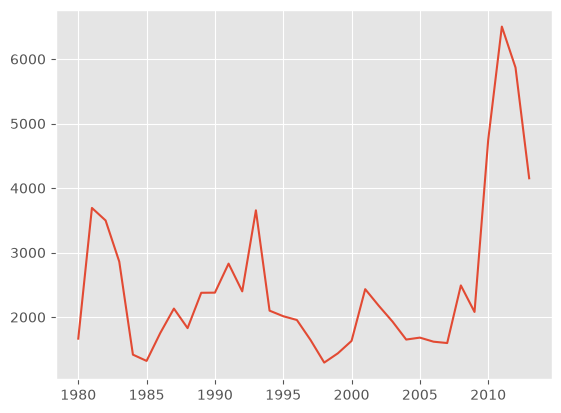

In [12]:
haiti.plot()

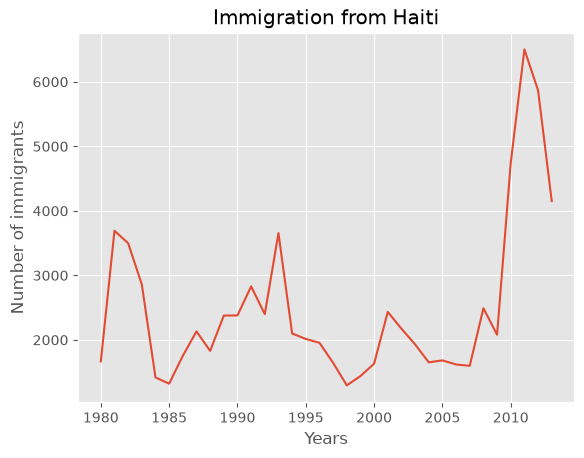

In [13]:
haiti.plot(kind='line')

plt.title('Immigration from Haiti')
plt.ylabel('Number of immigrants')
plt.xlabel('Years')

plt.show() # need this line to show the updates made to the figure

**Annotating the 2010 spike.** The years are text, so the x-axis counts slots 0–33, not years. Converting the index to integers turns it into a real number line, so the label can be placed at a year.

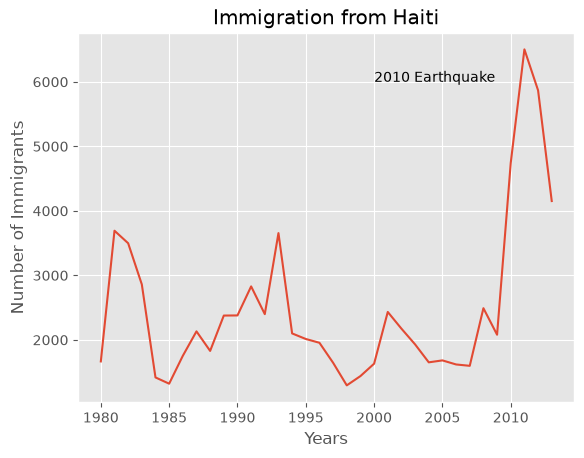

In [14]:
haiti.index = haiti.index.map(int) 
haiti.plot(kind='line')

plt.title('Immigration from Haiti')
plt.ylabel('Number of Immigrants')
plt.xlabel('Years')

# annotate the 2010 Earthquake. 
# syntax: plt.text(x, y, label)
plt.text(2000, 6000, '2010 Earthquake') # see note below

plt.show() 

### China vs India

In [15]:
china_india = df_can.loc[['China', 'India'], years]
china_india

,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
China,5123,6682,3308,1863,1527,1816,1960,2643,2758,4323,...,36619,42584,33518,27642,30037,29622,30391,28502,33024,34129
India,8880,8670,8147,7338,5704,4211,7150,10189,11522,10343,...,28235,36210,33848,28742,28261,29456,34235,27509,30933,33087


My first attempt plotted the table as it was: countries as rows, years as columns. `.plot()` put the two countries on the x-axis and drew one line per year, which is the wrong way round.

<Axes: >

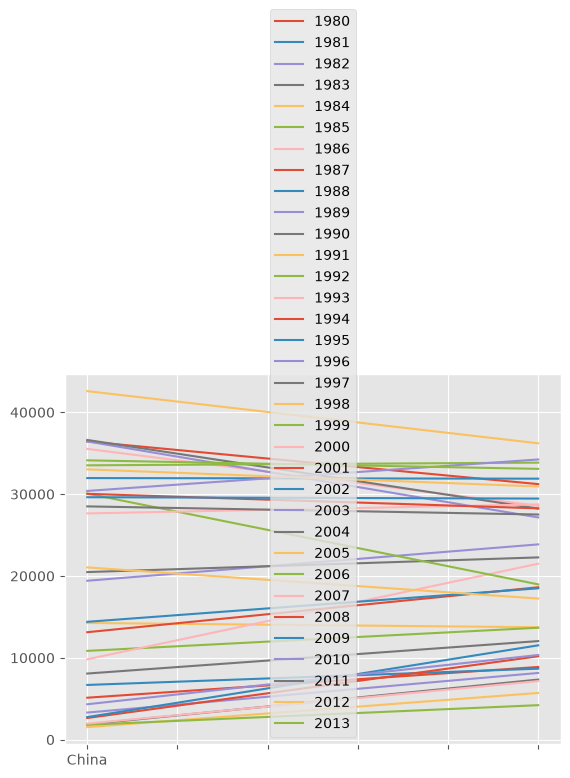

In [16]:
china_india.plot(kind='line')

Transposing makes the years the index, so they go on the x-axis, with one line per country.

In [17]:
china_india = china_india.T      # flip: years become rows, countries become columns
china_india.head()               # check: index = 1980, 1981, …  columns = China, India

,China,India
1980,5123,8880
1981,6682,8670
1982,3308,8147
1983,1863,7338
1984,1527,5704


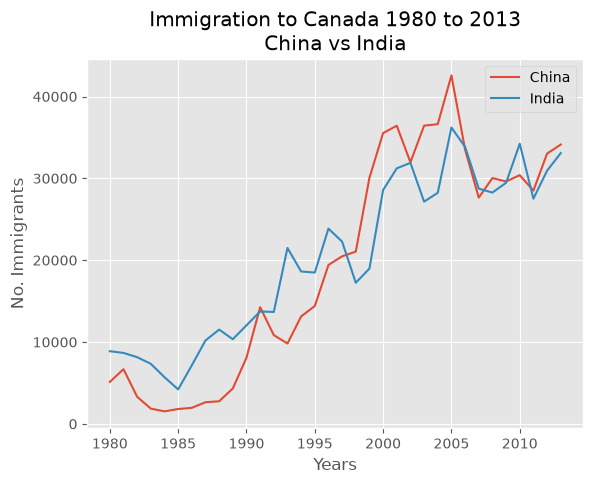

In [18]:
china_india.plot(kind='line')
plt.title('Immigration to Canada 1980 to 2013\nChina vs India')
plt.xlabel('Years')
plt.ylabel('No. Immigrants')
plt.show()

### Top 5 countries

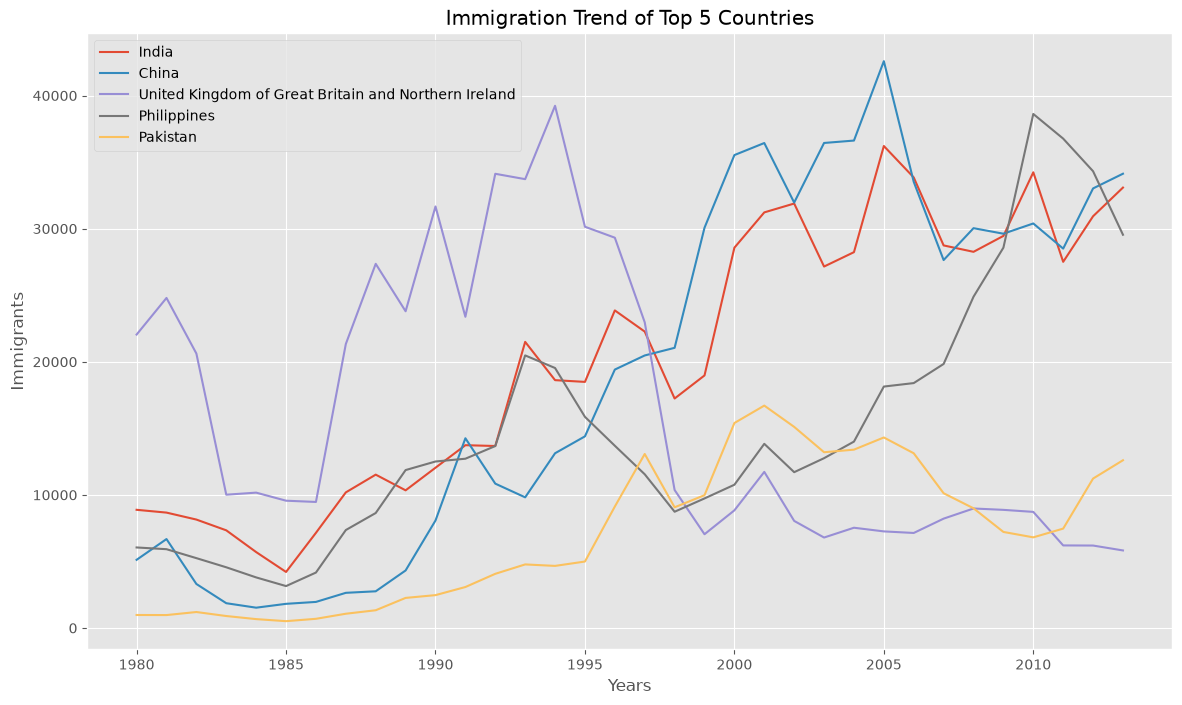

In [19]:
top5 = df_can.nlargest(5, 'Total')    # whole rows of the top 5, all columns kept
top5 = top5[years].T                  # keep the year columns, then flip
top5.plot(kind='line', figsize=(14, 8))
plt.title('Immigration Trend of Top 5 Countries')
plt.xlabel('Years')
plt.ylabel('Immigrants')
plt.show()

## What I took away

- `.plot()` puts the **index** on the x-axis and draws one line per **column**. A plot with a huge legend means the table is the wrong way round, and `.T` fixes it.
- With years as text, the x-axis is a row of named slots (0, 1, 2 …). Converting them to integers makes it a real number line, so `plt.text(2000, …)` lands on the year 2000.
- `df_can.nlargest(5, 'Total')` keeps the whole rows; `df_can['Total'].nlargest(5)` would drop the year columns needed for the plot.
- The Haiti spike is a real event, the 2010 earthquake, which is why spikes get investigated, not deleted.